# ICT-15d — Cochaîne de Čech pondérée : obstruction intra-substrat

## Question et hypothèses

Sur un substrat donné, plusieurs proxys locaux se recollent-ils en une mesure globale unique, ou leurs relations manifestent-elles une obstruction structurelle ? La comparaison inter-substrats de `ict.meta_proxy` (« Phase Zéro ») mesure la dispersion de niveaux bruts — gap spectral et sensibilités moyenne/max — donc un écart d'échelle, même normalisé. Elle ne suffit pas à identifier un motif de désaccord structurel intra-substrat. Le test examine cette structure relationnelle au moyen de la cochaîne de Čech.

Ce carnet est le jumeau C# de [ICT-15d-CechObstruction-Python.ipynb](ICT-15d-CechObstruction-Python.ipynb). Il rejoue les mêmes substrats, les mêmes proxys et le même verdict, avec des types .NET natifs : aucune bibliothèque de calcul numérique n'est requise pour la couche Čech. Deux primitives sont remplacées et déclarées plus bas — le générateur aléatoire et la décomposition en valeurs singulières.

## Objet mathématique et protocole

La trajectoire est découpée en fenêtres contiguës ; la valeur de chaque proxy dans une fenêtre constitue une section locale.

| Objet Čech | Ici | Signification |
|---|---|---|
| **Recouvrement double** (cobord, 1-cochaîne) | `Cech.TransportResidual(s_i, s_j)` | résidu après ajustement affine ; absorbé s'il est purement affine |
| **Recouvrement triple** (cocycle, 2-cochaîne) | `Cech.Holonomy(r_ij, r_jk, r_ki)` | somme cyclique des résidus ; non nulle, elle signale un désaccord cyclique |
| **Non-nullité de la classe** | `MeanCocycle` (cocycle triple) | cocycle nul : proxys recollables (cas trivial) ; non nul : obstruction candidate |

Le verdict est falsifiable : `NON_TRIVIAL` si le cocycle triple **et** le ratio d'obstruction dépassent chacun leur plancher (0.05) et si les holonomies ont une direction majoritaire (`SignConsistency` ≥ 0.5) ; `TRIVIAL` si l'un des deux est sous son plancher ; `INCONCLUSIVE` si moins de trois proxys sont disponibles ou si le cocycle est non nul sans direction majoritaire. La dimensionnalité SVD reste rapportée comme témoin et ne décide pas du verdict.

## Protocole expérimental

Sur au moins un substrat ICT, déterminer si la lecture-obstruction change une décision expérimentale ou une visualisation, par exemple en reclassant un régime « dispersion » en régime « obstruction » ou en disqualifiant un proxy. Le résultat négatif est également informatif : si, sur tous les substrats, les proxys se réduisent à un signal latent 1D, le candidat ne constate pas d'obstruction et cette piste transverse échoue proprement.

Le protocole reprend les substrats d'ICT-15c : **Gray-Scott** (Turing), **Axelrod** (réplicateur), **Grokking** (compression crossover) et **May** (ICT-8, pâturage bistable), avec graines fixées pour des expériences déterministes.

> **Statut épistémique** — **hypothèse** : La cochaîne de Čech pondérée discrimine les substrats (`NON_TRIVIAL` = les proxys ne se recollent pas en 1D). Portée et détail dans la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md).

In [1]:
#r "nuget: ScottPlot, 5.0.55"
// Appareil du jumeau C# : RNG deterministe, substrats, organes spectral et de
// sensibilite, plus la cochaîne de Cech. Le RNG numpy (PCG64) n'est pas
// reproductible en .NET : on le remplace par un xorshift64* seede (meme choix
// que les jumeaux ICT-15 et ICT-15c), lui aussi deterministe par graine.
// Les grandeurs deterministes sont identiques a la source ; les grandeurs
// stochastiques sont comparees a tolerance de Monte-Carlo (cf.
// twin_pairs.d/ict-15d-cechobstruction.yaml).
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using ScottPlot;
using Microsoft.DotNet.Interactive;

// ---------------------------------------------------------------------------
// RNG : xorshift64*
// ---------------------------------------------------------------------------
public sealed class Rng64
{
    private ulong _x;
    private double _spare;
    private bool _hasSpare;

    public Rng64(ulong seed)
    {
        _x = seed == 0UL ? 0x9E3779B97F4A7C15UL : seed;
    }

    public ulong NextUInt64()
    {
        ulong x = _x;
        x ^= x >> 12;
        x ^= x << 25;
        x ^= x >> 27;
        _x = x;
        return x * 0x2545F4914F6CDD1DUL;
    }

    public double NextDouble() => (NextUInt64() >> 11) * (1.0 / 9007199254740992.0);

    public int NextInt(int lo, int hi)
    {
        if (hi <= lo) return lo;
        return lo + (int)(NextDouble() * (hi - lo));
    }

    // Box-Muller avec reserve (equivalent de Generator.standard_normal)
    public double NextNormal()
    {
        if (_hasSpare) { _hasSpare = false; return _spare; }
        double u1, u2, s;
        do
        {
            u1 = 2.0 * NextDouble() - 1.0;
            u2 = 2.0 * NextDouble() - 1.0;
            s = u1 * u1 + u2 * u2;
        } while (s >= 1.0 || s == 0.0);
        double f = Math.Sqrt(-2.0 * Math.Log(s) / s);
        _spare = u2 * f;
        _hasSpare = true;
        return u1 * f;
    }
}

// ---------------------------------------------------------------------------
// Statistiques (conventions numpy : quantile 'linear', digitize a droite exclue,
// ecart-type de population ddof=0)
// ---------------------------------------------------------------------------
public static class Stats
{
    public static double[] Linspace(double a, double b, int n)
    {
        var r = new double[n];
        if (n <= 0) return r;
        if (n == 1) { r[0] = a; return r; }
        double step = (b - a) / (n - 1);
        for (int i = 0; i < n - 1; i++) r[i] = a + i * step;
        r[n - 1] = b;
        return r;
    }

    public static double[] Quantiles(IEnumerable<double> data, double[] qs)
    {
        var sorted = data.ToArray();
        Array.Sort(sorted);
        int n = sorted.Length;
        var res = new double[qs.Length];
        if (n == 0) return res;
        for (int k = 0; k < qs.Length; k++)
        {
            double pos = qs[k] * (n - 1);
            int lo = (int)Math.Floor(pos);
            if (lo < 0) lo = 0;
            if (lo > n - 1) lo = n - 1;
            int hi = Math.Min(lo + 1, n - 1);
            double frac = pos - lo;
            res[k] = sorted[lo] + frac * (sorted[hi] - sorted[lo]);
        }
        return res;
    }

    // np.digitize(x, bins) : index i tel que bins[i-1] <= x < bins[i]
    public static int[] Digitize(double[] x, double[] bins)
    {
        var r = new int[x.Length];
        for (int i = 0; i < x.Length; i++)
        {
            int idx = 0;
            while (idx < bins.Length && x[i] >= bins[idx]) idx++;
            r[i] = idx;
        }
        return r;
    }

    public static double[] Flatten(double[,] a)
    {
        int n = a.GetLength(0), m = a.GetLength(1);
        var r = new double[n * m];
        int k = 0;
        for (int i = 0; i < n; i++)
            for (int j = 0; j < m; j++) r[k++] = a[i, j];
        return r;
    }

    public static double Mean(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double s = 0.0;
        for (int i = 0; i < v.Count; i++) s += v[i];
        return s / v.Count;
    }

    public static double StdPop(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double m = Mean(v);
        double s = 0.0;
        for (int i = 0; i < v.Count; i++) { double d = v[i] - m; s += d * d; }
        return Math.Sqrt(s / v.Count);
    }

    public static double Percentile(double[] v, double p)
        => v.Length == 0 ? 0.0 : Quantiles(v, new[] { p })[0];

    public static double Max(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double m = v[0];
        for (int i = 1; i < v.Count; i++) if (v[i] > m) m = v[i];
        return m;
    }

    public static double Min(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double m = v[0];
        for (int i = 1; i < v.Count; i++) if (v[i] < m) m = v[i];
        return m;
    }
}

// ---------------------------------------------------------------------------
// Substrat 1 : Gray-Scott (port de ict.reaction_diffusion)
// ---------------------------------------------------------------------------
public sealed class GrayScott
{
    public double F { get; }
    public double Kill { get; }
    public double Du { get; }
    public double Dv { get; }
    public double Dt { get; }

    public GrayScott(double feed = 0.0367, double kill = 0.0649, double du = 0.16, double dv = 0.08, double step = 1.0)
    {
        F = feed; Kill = kill; Du = du; Dv = dv; Dt = step;
    }

    // Stencil 5 points a bords periodiques. L'ordre d'association reproduit
    // celui de ict.reaction_diffusion.laplacian :
    //   roll(+1, axe0) + roll(-1, axe0) + roll(+1, axe1) + roll(-1, axe1) - 4*f
    public static double[,] Laplacian(double[,] field)
    {
        int n = field.GetLength(0), m = field.GetLength(1);
        var r = new double[n, m];
        for (int i = 0; i < n; i++)
        {
            int im = (i - 1 + n) % n;
            int ip = (i + 1) % n;
            for (int j = 0; j < m; j++)
            {
                int jm = (j - 1 + m) % m;
                int jp = (j + 1) % m;
                r[i, j] = field[im, j] + field[ip, j] + field[i, jm] + field[i, jp] - 4.0 * field[i, j];
            }
        }
        return r;
    }

    public (double[,] U, double[,] V) Seed(int n = 96, int block = 12, double noise = 0.02, Rng64 rng = null)
    {
        var U = new double[n, n];
        var V = new double[n, n];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++) U[i, j] = 1.0;
        int lo = n / 2 - block / 2;
        int hi = lo + block;
        for (int i = lo; i < hi; i++)
            for (int j = lo; j < hi; j++) { U[i, j] = 0.50; V[i, j] = 0.25; }
        if (noise > 0.0)
        {
            var g = rng ?? new Rng64(0UL);
            for (int i = 0; i < n; i++)
                for (int j = 0; j < n; j++)
                {
                    U[i, j] += noise * g.NextNormal();
                    V[i, j] += noise * g.NextNormal();
                }
        }
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++)
            {
                U[i, j] = Math.Clamp(U[i, j], 0.0, 1.0);
                V[i, j] = Math.Clamp(V[i, j], 0.0, 1.0);
            }
        return (U, V);
    }

    public (double[,] U, double[,] V) Step(double[,] U, double[,] V)
    {
        var lapU = Laplacian(U);
        var lapV = Laplacian(V);
        int n = U.GetLength(0), m = U.GetLength(1);
        var Un = new double[n, m];
        var Vn = new double[n, m];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < m; j++)
            {
                double reaction = U[i, j] * V[i, j] * V[i, j];
                Un[i, j] = Math.Clamp(U[i, j] + Dt * (Du * lapU[i, j] - reaction + F * (1.0 - U[i, j])), 0.0, 1.0);
                Vn[i, j] = Math.Clamp(V[i, j] + Dt * (Dv * lapV[i, j] + reaction - (F + Kill) * V[i, j]), 0.0, 1.0);
            }
        return (Un, Vn);
    }

    public (double[,] U, double[,] V) Run(double[,] U, double[,] V, int steps)
    {
        for (int t = 0; t < steps; t++)
        {
            var s = Step(U, V);
            U = s.U; V = s.V;
        }
        return (U, V);
    }
}

// ---------------------------------------------------------------------------
// Substrat 2 : Axelrod (port de ict.strategic_morphodynamics)
// ---------------------------------------------------------------------------
public delegate int StrategyFn(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng);

public static class Ipd
{
    public const int C = 0;
    public const int D = 1;
    public static readonly double T = 5.0;
    public static readonly double R = 3.0;
    public static readonly double P = 1.0;
    public static readonly double S = 0.0;

    public static (double a, double b) PayoffPair(int a, int b)
    {
        if (a == C && b == C) return (R, R);
        if (a == C && b == D) return (S, T);
        if (a == D && b == C) return (T, S);
        return (P, P);
    }

    public static int AllC(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng) => C;
    public static int AllD(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng) => D;

    public static int Tft(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
        => opp.Count == 0 ? C : opp[opp.Count - 1];

    // Seule strategie consommatrice du RNG (protocole etendu #13322).
    public static int GTft(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
    {
        if (opp.Count == 0) return C;
        if (opp[opp.Count - 1] == C) return C;
        return rng.NextDouble() < 1.0 / 3.0 ? C : D;
    }

    public static int Pavlov(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
    {
        if (own.Count == 0) return C;
        int last = own[own.Count - 1];
        int oppLast = opp[opp.Count - 1];
        var (pa, _) = PayoffPair(last, oppLast);
        bool won = pa >= R;
        return won ? last : 1 - last;
    }

    public static int Grim(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
    {
        for (int i = 0; i < opp.Count; i++) if (opp[i] == D) return D;
        return C;
    }

    // Ordre d'insertion identique au dict Python (dict preserve l'ordre).
    public static List<KeyValuePair<string, StrategyFn>> MakeStrategies()
    {
        var l = new List<KeyValuePair<string, StrategyFn>>();
        l.Add(new KeyValuePair<string, StrategyFn>("allc", AllC));
        l.Add(new KeyValuePair<string, StrategyFn>("alld", AllD));
        l.Add(new KeyValuePair<string, StrategyFn>("tft", Tft));
        l.Add(new KeyValuePair<string, StrategyFn>("gtft", GTft));
        l.Add(new KeyValuePair<string, StrategyFn>("pavlov", Pavlov));
        l.Add(new KeyValuePair<string, StrategyFn>("grim", Grim));
        return l;
    }

    public static (double g1, double g2) PlayMatch(StrategyFn s1, StrategyFn s2, int nRounds, double noise, Rng64 rng)
    {
        var own1 = new List<int>();
        var own2 = new List<int>();
        double g1 = 0.0, g2 = 0.0;
        for (int t = 0; t < nRounds; t++)
        {
            int a = s1(own1, own2, rng);
            int b = s2(own2, own1, rng);
            if (noise > 0.0)
            {
                if (rng.NextDouble() < noise) a = 1 - a;
                if (rng.NextDouble() < noise) b = 1 - b;
            }
            var (pa, pb) = PayoffPair(a, b);
            g1 += pa; g2 += pb;
            own1.Add(a); own2.Add(b);
        }
        return (g1 / nRounds, g2 / nRounds);
    }

    public static double[,] PayoffMatrix(List<KeyValuePair<string, StrategyFn>> strategies,
                                         int nRounds, int nReps, Rng64 rng)
    {
        int n = strategies.Count;
        var A = new double[n, n];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++)
            {
                double sum = 0.0;
                for (int r = 0; r < nReps; r++)
                {
                    var (gi, _) = PlayMatch(strategies[i].Value, strategies[j].Value, nRounds, 0.0, rng);
                    sum += gi;
                }
                A[i, j] = sum / nReps;
            }
        return A;
    }

    public static double[,] ReplicatorTrajectory(double[,] A, double[] x0, int nSteps)
    {
        int n = x0.Length;
        var x = (double[])x0.Clone();
        double total = 0.0;
        for (int i = 0; i < n; i++) total += x[i];
        for (int i = 0; i < n; i++) x[i] /= total;
        var traj = new double[nSteps + 1, n];
        for (int i = 0; i < n; i++) traj[0, i] = x[i];
        for (int t = 0; t < nSteps; t++)
        {
            var f = new double[n];
            for (int i = 0; i < n; i++)
            {
                double s = 0.0;
                for (int j = 0; j < n; j++) s += A[i, j] * x[j];
                f[i] = s;
            }
            double avg = 0.0;
            for (int i = 0; i < n; i++) avg += f[i] * x[i];
            if (avg < 1e-12) break;
            double tot = 0.0;
            for (int i = 0; i < n; i++)
            {
                x[i] = Math.Max(0.0, x[i] * f[i] / avg);
                tot += x[i];
            }
            if (tot > 1e-12)
                for (int i = 0; i < n; i++) x[i] /= tot;
            for (int i = 0; i < n; i++) traj[t + 1, i] = x[i];
        }
        return traj;
    }
}

// ---------------------------------------------------------------------------
// Substrat 4 : May (port de ict.bistable.GrazingModel.simulate_sde)
// ---------------------------------------------------------------------------
public sealed class Grazing
{
    public double R { get; }
    public double K { get; }
    public double H { get; }

    public Grazing(double r = 1.0, double k = 10.0, double h = 1.0) { R = r; K = k; H = h; }

    public double Rate(double x, double c)
        => R * x * (1.0 - x / K) - c * x * x / (x * x + H * H);

    public double[] SimulateSde(double c, double x0, double sigma, double dt, int T, ulong seed)
    {
        var g = new Rng64(seed);
        double sq = Math.Sqrt(dt);
        double x = x0;
        var xs = new double[T];
        for (int t = 0; t < T; t++)
        {
            x = x + dt * Rate(x, c) + sigma * sq * g.NextNormal();
            if (x < 0.0) x = 0.0;
            xs[t] = x;
        }
        return xs;
    }
}

// ---------------------------------------------------------------------------
// Organe spectral (port de ict.spectral : matrice de transition, graphe
// symetrique sans boucle, Laplacien, gap)
// ---------------------------------------------------------------------------
public static class Spectral
{
    // P[s, t] += 1 seulement si les deux indices sont dans [0, n) ; les paires
    // hors bornes sont silencieusement ignorees (convention de la source).
    public static double[,] TransitionMatrix(IReadOnlyList<int> states, int nSymbols, double eps = 1e-9)
    {
        var P = new double[nSymbols, nSymbols];
        for (int i = 0; i < nSymbols; i++)
            for (int j = 0; j < nSymbols; j++) P[i, j] = eps;
        for (int t = 0; t + 1 < states.Count; t++)
        {
            int s = states[t], u = states[t + 1];
            if (s >= 0 && s < nSymbols && u >= 0 && u < nSymbols) P[s, u] += 1.0;
        }
        for (int i = 0; i < nSymbols; i++)
        {
            double sum = 0.0;
            for (int j = 0; j < nSymbols; j++) sum += P[i, j];
            if (sum > 0.0)
                for (int j = 0; j < nSymbols; j++) P[i, j] /= sum;
        }
        return P;
    }

    public static double[,] TransitionGraph(IReadOnlyList<int> states, int nSymbols)
    {
        var P = TransitionMatrix(states, nSymbols);
        var W = new double[nSymbols, nSymbols];
        for (int i = 0; i < nSymbols; i++)
            for (int j = 0; j < nSymbols; j++) W[i, j] = (P[i, j] + P[j, i]) / 2.0;
        for (int i = 0; i < nSymbols; i++) W[i, i] = 0.0;
        return W;
    }

    // Valeurs propres par Jacobi cyclique (matrice symetrique reelle).
    public static double[] SymmetricEigenvalues(double[,] A, int maxSweeps = 100)
    {
        int n = A.GetLength(0);
        var a = (double[,])A.Clone();
        for (int sweep = 0; sweep < maxSweeps; sweep++)
        {
            double off = 0.0;
            for (int i = 0; i < n; i++)
                for (int j = i + 1; j < n; j++) off += a[i, j] * a[i, j];
            if (off < 1e-30) break;
            for (int p = 0; p < n - 1; p++)
                for (int q = p + 1; q < n; q++)
                {
                    if (Math.Abs(a[p, q]) < 1e-18) continue;
                    double theta = (a[q, q] - a[p, p]) / (2.0 * a[p, q]);
                    double t = theta == 0.0
                        ? 1.0
                        : Math.Sign(theta) / (Math.Abs(theta) + Math.Sqrt(theta * theta + 1.0));
                    double c = 1.0 / Math.Sqrt(t * t + 1.0);
                    double s = t * c;
                    for (int k = 0; k < n; k++)
                    {
                        double akp = a[k, p], akq = a[k, q];
                        a[k, p] = c * akp - s * akq;
                        a[k, q] = s * akp + c * akq;
                    }
                    for (int k = 0; k < n; k++)
                    {
                        double apk = a[p, k], aqk = a[q, k];
                        a[p, k] = c * apk - s * aqk;
                        a[q, k] = s * apk + c * aqk;
                    }
                }
        }
        var eigs = new double[n];
        for (int i = 0; i < n; i++) eigs[i] = a[i, i];
        Array.Sort(eigs);
        return eigs;
    }

    public static double[] LaplacianSpectrum(double[,] W)
    {
        int n = W.GetLength(0);
        var L = new double[n, n];
        for (int i = 0; i < n; i++)
        {
            double d = 0.0;
            for (int j = 0; j < n; j++) d += W[i, j];
            for (int j = 0; j < n; j++) L[i, j] = -W[i, j];
            L[i, i] = d; // D - W, et W_ii = 0
        }
        return SymmetricEigenvalues(L);
    }

    public static double SpectralGap(double[,] W)
    {
        var eigs = LaplacianSpectrum(W);
        if (eigs.Length < 2) return double.NaN;
        return eigs[1] - eigs[0];
    }

    public static double SpectralGapOf(IReadOnlyList<int> states, int nSymbols)
        => SpectralGap(TransitionGraph(states, nSymbols));
}

// ---------------------------------------------------------------------------
// Organe de sensibilite (port de ict.sensitivity, correctif #9764 : voisinage
// lu sur les transitions OBSERVEES, pas sur le graphe lisse)
// ---------------------------------------------------------------------------
public sealed class SensitivitySummary
{
    public double max;
    public double mean;
    public double std;
    public double p95;
    public int n_visited;
}

public static class Sensitivity
{
    // Ids compacts par ordre de PREMIERE APPARITION ; leve si un nouveau label
    // apparait alors que n_symbols est deja atteint.
    public static int[] EncodeLabels(IReadOnlyList<int> states, int nSymbols)
    {
        var map = new Dictionary<int, int>();
        var ids = new int[states.Count];
        for (int i = 0; i < states.Count; i++)
        {
            int lab = states[i];
            if (!map.TryGetValue(lab, out int id))
            {
                if (map.Count >= nSymbols)
                    throw new InvalidOperationException(
                        $"trop de labels distincts pour n_symbols={nSymbols}");
                id = map.Count;
                map[lab] = id;
            }
            ids[i] = id;
        }
        return ids;
    }

    // Adjacence OBSERVEE : booleenne, symetrique, boucles exclues, paires hors
    // bornes ignorees, aucun lissage.
    public static bool[,] ObservedAdjacency(IReadOnlyList<int> states, int nSymbols)
    {
        var A = new bool[nSymbols, nSymbols];
        for (int t = 0; t + 1 < states.Count; t++)
        {
            int s = states[t], u = states[t + 1];
            if (s == u) continue;
            if (s < 0 || s >= nSymbols || u < 0 || u >= nSymbols) continue;
            A[s, u] = true;
            A[u, s] = true;
        }
        return A;
    }

    public static int[] Local(IReadOnlyList<int> states, int nSymbols, Func<int, int> f)
    {
        var ids = EncodeLabels(states, nSymbols);
        var A = ObservedAdjacency(ids, nSymbols);
        var fVals = new int[nSymbols];
        for (int i = 0; i < nSymbols; i++) fVals[i] = f(i);
        var s = new int[nSymbols];
        for (int x = 0; x < nSymbols; x++)
        {
            int count = 0;
            for (int y = 0; y < nSymbols; y++)
                if (A[x, y] && fVals[y] != fVals[x]) count++;
            s[x] = count;
        }
        return s;
    }

    // Les noeuds visites occupent les ids 0..n_visited-1 (encodage compact par
    // premiere apparition) : le prefixe suffit.
    public static SensitivitySummary Distribution(IReadOnlyList<int> states, int nSymbols, Func<int, int> f)
    {
        var s = Local(states, nSymbols, f);
        var distinct = new HashSet<int>(states);
        int nVisited = distinct.Count;
        var visited = new List<double>();
        for (int i = 0; i < Math.Min(nVisited, s.Length); i++) visited.Add(s[i]);
        return new SensitivitySummary
        {
            max = visited.Count == 0 ? 0.0 : Stats.Max(visited),
            mean = visited.Count == 0 ? 0.0 : Stats.Mean(visited),
            std = visited.Count == 0 ? 0.0 : Stats.StdPop(visited),
            p95 = visited.Count == 0 ? 0.0 : Stats.Percentile(visited.ToArray(), 95),
            n_visited = nVisited
        };
    }
}


// ---------------------------------------------------------------------------
// Cochaine de Cech (port de ict.cech_obstruction) : chaque proxy devient une
// section locale ; le cobord mesure le desaccord residuel apres ajustement
// affine par paire, le cocycle mesure l'holonomie cyclique sur les triplets.
// Un desaccord purement affine est absorbe par le cobord et n'est pas une
// obstruction ; seule une holonomie stable signale un defaut de recollement.
// ---------------------------------------------------------------------------
public sealed class TransportResidual
{
    public double[] Residual;
    public double A;
    public double B;
    public double Norm;
    public double Cosine;
}

public sealed class HolonomySummary
{
    public double Holonomy;
    public double MaxAbs;
    public double SignConsistency;
}

public sealed class CechReport
{
    public int NProxies;
    public int NWindows;
    public Dictionary<string, double> PairwiseResiduals = new();
    public double MeanCoboundary;
    public Dictionary<string, double> TripleHolonomies = new();
    public double MeanCocycle;
    public double ObstructionRatio;
    public double SignConsistency;
    public int EffectiveRank;
    public double S2OverS1;
}

public static class Cech
{
    // proxy_sections : fenetres contigues NON recouvrantes de `windowSize`
    // transitions, donc `windowSize + 1` etats par fenetre. Un decoupage
    // glissant correlerait les sections par construction et masquerait
    // l'obstruction que l'on cherche a mesurer.
    public static Dictionary<string, double[]> ProxySections(
        IReadOnlyList<int> states,
        int nSymbols,
        int windowSize,
        IReadOnlyList<KeyValuePair<string, Func<IReadOnlyList<int>, int, double>>> proxies)
    {
        if (nSymbols < 2) throw new ArgumentException($"n_symbols >= 2 requis (recu {nSymbols}).");
        if (windowSize < 1) throw new ArgumentException($"window_size >= 1 requis (recu {windowSize}).");
        if (proxies.Count < 2) throw new ArgumentException($">= 2 proxys requis pour un recouvrement (recu {proxies.Count}).");
        if (states.Count < windowSize + 1)
            throw new ArgumentException($"trajectoire trop courte ({states.Count} etats) pour window_size={windowSize}.");

        // np.arange(0, N - windowSize, windowSize) : autant de departs que
        // ceil((N - windowSize) / windowSize), soit (N - 1) / windowSize en
        // division entiere.
        int nWin = (states.Count - 1) / windowSize;
        var sections = new Dictionary<string, double[]>();
        foreach (var kv in proxies)
        {
            var vals = new double[nWin];
            for (int k = 0; k < nWin; k++)
            {
                int s0 = k * windowSize;
                var window = new int[windowSize + 1];
                for (int t = 0; t <= windowSize; t++) window[t] = states[s0 + t];
                vals[k] = kv.Value(window, nSymbols);
            }
            sections[kv.Key] = vals;
        }
        return sections;
    }

    // Centre-reduit chaque section : on ne compare pas les niveaux bruts mais
    // la structure relative. Une section constante (proxy insensible aux
    // fenetres) devient un vecteur nul -- elle ne contribue ni au cobord ni au
    // cocycle, plutot que d'injecter une division par zero.
    public static Dictionary<string, double[]> NormalizeSections(
        IReadOnlyDictionary<string, double[]> sections)
    {
        var output = new Dictionary<string, double[]>();
        foreach (var kv in sections)
        {
            var s = kv.Value;
            double mu = Stats.Mean(s);
            double sigma = Stats.StdPop(s);
            var norm = new double[s.Length];
            if (sigma >= 1e-12)
                for (int i = 0; i < s.Length; i++) norm[i] = (s[i] - mu) / sigma;
            output[kv.Key] = norm;
        }
        return output;
    }

    // Dimensionnalite effective du faisceau : valeurs singulieres de la matrice
    // (une ligne par proxy). Sur une matrice a peu de lignes et beaucoup de
    // colonnes, elles s'obtiennent exactement comme racines des valeurs propres
    // de la matrice de Gram M M^T -- de taille n_proxies carree.
    public static (double s1, double s2, double s3, double s2OverS1, int rank)
        EffectiveDimensionality(IReadOnlyDictionary<string, double[]> sections, bool normalize = true)
    {
        var secs = normalize ? NormalizeSections(sections) : sections;
        int m = secs.Count;
        if (m == 0) return (0.0, 0.0, 0.0, 0.0, 0);

        var rows = new List<double[]>();
        foreach (var kv in secs) rows.Add(kv.Value);
        int n = rows[0].Length;

        var gram = new double[m, m];
        for (int i = 0; i < m; i++)
            for (int j = i; j < m; j++)
            {
                double acc = 0.0;
                for (int k = 0; k < n; k++) acc += rows[i][k] * rows[j][k];
                gram[i, j] = acc;
                gram[j, i] = acc;
            }

        // Spectral.SymmetricEigenvalues trie par ordre croissant : on relit a
        // l'envers pour obtenir s1 >= s2 >= s3.
        var ev = Spectral.SymmetricEigenvalues(gram);
        var sv = new double[ev.Length];
        for (int i = 0; i < ev.Length; i++)
            sv[i] = Math.Sqrt(Math.Max(ev[ev.Length - 1 - i], 0.0));
        for (int i = 0; i < sv.Length; i++) sv[i] = Math.Max(sv[i], 1e-12);

        double s1 = sv.Length > 0 ? sv[0] : 0.0;
        double s2 = sv.Length > 1 ? sv[1] : 0.0;
        double s3 = sv.Length > 2 ? sv[2] : 0.0;

        // Une valeur singuliere sous 10 % de s1 est tenue pour negligeable.
        const double rankFloor = 0.1;
        int rank = 0;
        for (int i = 0; i < sv.Length; i++) if (sv[i] >= rankFloor * s1) rank++;

        return (s1, s2, s3, s1 > 0 ? s2 / s1 : 0.0, rank);
    }

    // Cobord (1-cochaine) : moindres carres de s_i ~ a*s_j + b, residu
    // r = s_i - (a*s_j + b). Ce qui reste apres avoir retire la meilleure
    // relation affine est exactement ce qui n'est pas un simple changement
    // d'echelle ou de niveau.
    public static TransportResidual TransportResidual(double[] si, double[] sj)
    {
        if (si.Length != sj.Length)
            throw new ArgumentException($"sections de formes differentes : {si.Length} vs {sj.Length}");
        if (si.Length < 2)
            throw new ArgumentException(">= 2 fenetres requis pour un ajustement affine.");

        double mi = Stats.Mean(si);
        double mj = Stats.Mean(sj);
        double sdj = Stats.StdPop(sj);
        double varj = sdj * sdj;

        double a, b;
        if (varj < 1e-12)
        {
            // s_j constante : aucune relation affine n'est definie, rien n'est
            // explique par s_j, le residu est s_i lui-meme (centre).
            a = 0.0;
            b = mi;
        }
        else
        {
            double cov = 0.0;
            for (int k = 0; k < si.Length; k++) cov += (si[k] - mi) * (sj[k] - mj);
            cov /= si.Length;
            a = cov / varj;
            b = mi - a * mj;
        }

        var residual = new double[si.Length];
        for (int k = 0; k < si.Length; k++) residual[k] = si[k] - (a * sj[k] + b);

        double acc = 0.0;
        for (int k = 0; k < residual.Length; k++) acc += residual[k] * residual[k];
        double norm = Math.Sqrt(acc / residual.Length);

        double sci = 0.0, scj = 0.0, scij = 0.0;
        for (int k = 0; k < si.Length; k++)
        {
            double ci = si[k] - mi;
            double cj = sj[k] - mj;
            sci += ci * ci;
            scj += cj * cj;
            scij += ci * cj;
        }
        double denom = Math.Sqrt(sci / si.Length) * Math.Sqrt(scj / sj.Length);
        double cosine = denom > 1e-12 ? (scij / si.Length) / denom : 0.0;

        return new TransportResidual { Residual = residual, A = a, B = b, Norm = norm, Cosine = cosine };
    }

    // Cocycle (2-cochaine) : holonomie h = r_ij + r_jk + r_ki mesuree par
    // fenetre. Si les sections proviennent d'une mesure globale coherente, la
    // somme cyclique s'annule. La coherence de signe distingue une obstruction
    // directionnelle d'un residu de bruit qui oscille autour de zero.
    public static HolonomySummary Holonomy(double[] rIJ, double[] rJK, double[] rKI)
    {
        int n = rIJ.Length;
        var h = new double[n];
        for (int k = 0; k < n; k++) h[k] = rIJ[k] + rJK[k] + rKI[k];

        double acc = 0.0, maxAbs = 0.0;
        int pos = 0, neg = 0;
        for (int k = 0; k < n; k++)
        {
            acc += h[k] * h[k];
            double a = Math.Abs(h[k]);
            if (a > maxAbs) maxAbs = a;
            if (h[k] > 1e-9) pos++;
            else if (h[k] < -1e-9) neg++;
        }
        double rms = n > 0 ? Math.Sqrt(acc / n) : 0.0;
        double sign = n > 0 ? Math.Max((double)pos / n, (double)neg / n) : 0.0;

        return new HolonomySummary { Holonomy = rms, MaxAbs = maxAbs, SignConsistency = sign };
    }

    // Classe d'obstruction : tous les cobords par paires, tous les cocycles par
    // triplets, puis le rapport cocycle/cobord -- la fraction du desaccord qui
    // n'est PAS expliquee par les relations affines par paires.
    public static CechReport ObstructionClass(
        IReadOnlyDictionary<string, double[]> sections, bool normalize = true)
    {
        var secs = normalize ? NormalizeSections(sections) : sections;
        var names = new List<string>(secs.Keys);
        int n = names.Count;

        var residuals = new Dictionary<string, double[]>();
        var pairwise = new Dictionary<string, double>();
        for (int a = 0; a < n; a++)
            for (int b = a + 1; b < n; b++)
            {
                var res = TransportResidual(secs[names[a]], secs[names[b]]);
                string key = names[a] + "|" + names[b];
                pairwise[key] = res.Norm;
                residuals[key] = res.Residual;
            }

        double meanCoboundary = pairwise.Count > 0 ? pairwise.Values.Average() : 0.0;

        var triples = new Dictionary<string, double>();
        var signCons = new List<double>();
        if (n >= 3)
        {
            for (int a = 0; a < n; a++)
                for (int b = a + 1; b < n; b++)
                    for (int c = b + 1; c < n; c++)
                    {
                        string kAB = names[a] + "|" + names[b];
                        string kBC = names[b] + "|" + names[c];
                        string kAC = names[a] + "|" + names[c];
                        // Le triplet (a,b,c) est parcouru dans l'ordre cyclique
                        // a -> b -> c -> a. La paire (c,a) n'est jamais stockee
                        // dans cet ordre : on prend l'oppose du residu (a,c),
                        // ce qui est la meme chose au signe pres, et c'est
                        // precisement le signe que l'holonomie somme.
                        var rCA = new double[residuals[kAC].Length];
                        for (int k = 0; k < rCA.Length; k++) rCA[k] = -residuals[kAC][k];
                        var h = Holonomy(residuals[kAB], residuals[kBC], rCA);
                        triples[names[a] + "|" + names[b] + "|" + names[c]] = h.Holonomy;
                        signCons.Add(h.SignConsistency);
                    }
        }

        double meanCocycle = triples.Count > 0 ? triples.Values.Average() : 0.0;
        double signConsistency = signCons.Count > 0 ? signCons.Average() : 0.0;

        // Les sections sont deja normalisees : on demande la dimensionnalite
        // sans re-normaliser, pour ne pas ecraser une structure deja centree.
        var dim = EffectiveDimensionality(secs, normalize: false);

        return new CechReport
        {
            NProxies = n,
            NWindows = secs.Count > 0 ? secs[names[0]].Length : 0,
            PairwiseResiduals = pairwise,
            MeanCoboundary = meanCoboundary,
            TripleHolonomies = triples,
            MeanCocycle = meanCocycle,
            ObstructionRatio = meanCocycle / (meanCoboundary + 1e-12),
            SignConsistency = signConsistency,
            EffectiveRank = dim.rank,
            S2OverS1 = dim.s2OverS1
        };
    }

    // Verdict falsifiable. La mesure decisive est le cocycle triple : c'est lui
    // qui porte le defaut de recollement, pas la dimension du nuage. Le rang
    // SVD reste un temoin de forme, il ne decide pas. Sur ce banc le temoin
    // negatif axelrod porte un cocycle nul ET un rang 1 : les deux lectures y
    // concordent, le banc ne les departage pas (cf Lecture 4).
    public static string Verdict(
        CechReport report, double cocycleFloor = 0.05, double ratioFloor = 0.05, double signFloor = 0.5)
    {
        if (report.NProxies < 3) return "INCONCLUSIVE";
        if (report.MeanCocycle <= cocycleFloor || report.ObstructionRatio <= ratioFloor) return "TRIVIAL";
        if (report.SignConsistency < signFloor) return "INCONCLUSIVE";
        return "NON_TRIVIAL";
    }

    // Banc falsifiable : un jeu affine (trois proxys = transformations affines
    // d'un meme latent, donc recollables) et un jeu multi-dimensionnel (deux
    // latents independants, donc non recollables). L'instrument ne vaut que
    // s'il separe les deux.
    public static Dictionary<string, double> Test(int nWindows = 60, ulong seed = 0UL)
    {
        var rng = new Rng64(seed);

        var latent = new double[nWindows];
        for (int i = 0; i < nWindows; i++) latent[i] = rng.NextNormal();
        var affine = new Dictionary<string, double[]>
        {
            ["A"] = latent.Select(v => 2.5 * v + 10.0).ToArray(),
            ["B"] = latent.Select(v => -0.8 * v - 3.0).ToArray(),
            ["C"] = latent.Select(v => 1.3 * v + 7.0).ToArray()
        };
        var repAff = ObstructionClass(affine);
        string verdictAff = Verdict(repAff);

        var x = new double[nWindows];
        var y = new double[nWindows];
        for (int i = 0; i < nWindows; i++) { x[i] = rng.NextNormal(); y[i] = rng.NextNormal(); }
        var multi = new Dictionary<string, double[]>
        {
            ["A"] = x,
            ["B"] = y,
            ["C"] = x.Select((v, i) => v + y[i]).ToArray()
        };
        var repMul = ObstructionClass(multi);
        string verdictMul = Verdict(repMul);

        bool passes = verdictAff == "TRIVIAL" && verdictMul == "NON_TRIVIAL";
        return new Dictionary<string, double>
        {
            ["affine_s2_over_s1"] = repAff.S2OverS1,
            ["affine_coboundary"] = repAff.MeanCoboundary,
            ["affine_cocycle"] = repAff.MeanCocycle,
            ["affine_sign_consistency"] = repAff.SignConsistency,
            ["multi_s2_over_s1"] = repMul.S2OverS1,
            ["multi_coboundary"] = repMul.MeanCoboundary,
            ["multi_cocycle"] = repMul.MeanCocycle,
            ["multi_sign_consistency"] = repMul.SignConsistency,
            ["multi_effective_rank"] = repMul.EffectiveRank,
            ["passes"] = passes ? 1.0 : 0.0
        };
    }
}

// ---------------------------------------------------------------------------
// Palette viridis locale (rendu de la heatmap sans dependre de l'API
// Colormaps de ScottPlot, dont la surface varie d'une version a l'autre)
// ---------------------------------------------------------------------------
public static class Palette
{
    private static readonly byte[][] Stops =
    {
        new byte[] { 68, 1, 84 },
        new byte[] { 72, 40, 120 },
        new byte[] { 62, 74, 137 },
        new byte[] { 49, 104, 142 },
        new byte[] { 38, 130, 142 },
        new byte[] { 31, 158, 137 },
        new byte[] { 53, 183, 121 },
        new byte[] { 109, 205, 89 },
        new byte[] { 180, 222, 44 },
        new byte[] { 253, 231, 37 }
    };

    public static readonly ScottPlot.Color Blanc = new ScottPlot.Color(255, 255, 255);
    public static readonly ScottPlot.Color Noir = new ScottPlot.Color(0, 0, 0);

    public static ScottPlot.Color Viridis(double t)
    {
        t = Math.Clamp(t, 0.0, 1.0);
        double pos = t * (Stops.Length - 1);
        int i0 = (int)Math.Floor(pos);
        if (i0 >= Stops.Length - 1) i0 = Stops.Length - 2;
        double f = pos - i0;
        byte R = (byte)Math.Round(Stops[i0][0] + f * (Stops[i0 + 1][0] - Stops[i0][0]));
        byte G = (byte)Math.Round(Stops[i0][1] + f * (Stops[i0 + 1][1] - Stops[i0][1]));
        byte B = (byte)Math.Round(Stops[i0][2] + f * (Stops[i0 + 1][2] - Stops[i0][2]));
        return new ScottPlot.Color(R, G, B);
    }
}

// ---------------------------------------------------------------------------
// Culture (c.94 : les TROIS setters, sinon separateur decimal virgule)
// ---------------------------------------------------------------------------
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

Console.WriteLine("cech_obstruction porte en C#. Substrats pilotes : Gray-Scott, Axelrod, Grokking, May (ICT-8).");

The below script needs to be able to find the current output cell; this is an easy method to get it.

Installed Packages ScottPlot, 5.0.55

cech_obstruction porte en C#. Substrats pilotes : Gray-Scott, Axelrod, Grokking, May (ICT-8).


In [2]:
// Sanity check : reproduction du banc interne Cech.Test
// Affirme : banc affine -> TRIVIAL, banc multi-dim -> NON_TRIVIAL.
// Si cette discrimination echoue, l'instrument n'est pas capable de rendre
// le verdict positif sur les substrats reels (cf Prong B sota-not-workaround).
var bench = new List<Dictionary<string, double>>();
for (ulong seed = 0; seed < 8; seed++)
{
    var r = Cech.Test(60, seed);
    bench.Add(r);
    Console.WriteLine(
        $"seed={seed}: affine cocycle={r["affine_cocycle"]:F4}, s2/s1={r["affine_s2_over_s1"]:F3} | " +
        $"multi_cocycle={r["multi_cocycle"]:F4}, sign={r["multi_sign_consistency"]:F4}, " +
        $"s2/s1={r["multi_s2_over_s1"]:F3}, rank={(int)r["multi_effective_rank"]} | " +
        $"passes={r["passes"]:F0}");
}
double passesTotal = bench.Sum(r => r["passes"]);
Console.WriteLine($"\nBanc synthetique : {(int)passesTotal}/8 seeds passent (TRIVIAL + NON_TRIVIAL discrimines).");
if (passesTotal != 8.0) throw new Exception("Le banc interne doit passer 8/8 sur signaux synthetiques.");

seed=0: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=1.0315, sign=0.5000, s2/s1=0.772, rank=2 | passes=1


seed=1: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=0.9088, sign=0.5333, s2/s1=0.649, rank=2 | passes=1


seed=2: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=0.8649, sign=0.5167, s2/s1=0.654, rank=2 | passes=1


seed=3: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=1.1468, sign=0.5167, s2/s1=0.760, rank=2 | passes=1


seed=4: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=0.9466, sign=0.5167, s2/s1=0.687, rank=2 | passes=1


seed=5: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=1.0755, sign=0.5333, s2/s1=0.752, rank=2 | passes=1


seed=6: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=1.1121, sign=0.5333, s2/s1=0.734, rank=2 | passes=1


seed=7: affine cocycle=0.0000, s2/s1=0.000 | multi_cocycle=1.0113, sign=0.5500, s2/s1=0.729, rank=2 | passes=1



Banc synthetique : 8/8 seeds passent (TRIVIAL + NON_TRIVIAL discrimines).


## Lecture 1 -- Le banc synthétique : 8 seeds passent

Le sanity check reproduit le banc interne `Cech.Test` avec 8 seeds (0 à 7). Sur 60 fenêtres, chaque seed tire un latent gaussien et en déduit trois proxys affines (banc affine), puis deux latents indépendants dont le troisième proxy est la somme (banc multi-dimensionnel) ; la mesure qui **décide** est le cocycle triple. Pour les 8 seeds, le banc affine rend `MeanCocycle = 0.0000` (les trois proxys sont des transformations affines d'un même latent : ils se recollent en une mesure globale unique) tandis que le banc multi-dimensionnel rend un `MeanCocycle` entre **0.8649 et 1.1468** (deux latents indépendants : aucun recollement global n'existe). Le `s2/s1` reste imprimé comme **témoin de forme** — 0.000 pour l'affine, 0.649 à 0.772 pour le multi-dimensionnel — mais il ne décide plus : le témoin négatif axelrod, plus bas, porte un cocycle nul et un rang 1 — les deux lectures y concordent, et c'est le cocycle qui énonce la règle.

Les huit seeds discriminent de la même façon (`passes=1` à chaque ligne : affine `TRIVIAL`, multi-dimensionnel `NON_TRIVIAL`) — la sortie le résume en « Banc synthetique : 8/8 seeds passent » : la discrimination TRIVIAL / NON_TRIVIAL est stable au ré-échantillonnage. C'est la condition de validité du Prong B (sota-not-workaround) : si le banc interne échouait, le verdict positif rendu plus bas sur les substrats réels ne vaudrait rien.

## Banc expérimental : quatre substrats

On réutilise les mêmes substrats qu'ICT-15c (Phase Zéro déjà livrée, PR #7578 + PR #9328
désaturation) et on leur applique la cochaîne de Čech pondérée. Trois proxys par substrat :

- `spectral_gap` (gap spectral du Laplacien du graphe de transition)
- `sens_mean` (sensibilité moyenne, `f(x) = x` identité sur le vocabulaire)
- `sens_max` (sensibilité max, même fonction)

Choix de la fenêtre (`window_size`) : adapté à la longueur de chaque trajectoire, pour avoir
autour de trente fenêtres contiguës par substrat (assez pour mesurer une structure non triviale, pas trop
pour ne pas fragmenter).

In [3]:
// --- Substrat 1 : Gray-Scott Turing patterns (F=0.030, k=0.062) ---
// Les parametres F/k different de ceux du jumeau 15c (0.035 / 0.065) : la source
// Python de ce carnet porte sa propre fenetre Turing. On la reproduit telle quelle,
// sinon les trajectoires ne sont pas les memes instances.
var gs = new GrayScott(0.030, 0.062, 0.16, 0.08, 1.0);
var gsSeedRng = new Rng64(20260720UL);
var gsInit = gs.Seed(64, 12, 0.02, gsSeedRng);
var gsRun = gs.Run(gsInit.U, gsInit.V, 800);
var uFlat = Stats.Flatten(gsRun.U);
var uQ = Stats.Quantiles(uFlat, new[] { 0.25, 0.5, 0.75 });
var grayScottStates = Stats.Digitize(uFlat, uQ).ToList();
int nSymbolsGs = 4;
Console.WriteLine($"gray_scott : len={grayScottStates.Count}, n_symbols={nSymbolsGs}, " +
                  $"unique={grayScottStates.Distinct().Count()}, " +
                  $"U range=[{Stats.Min(uFlat):F4}, {Stats.Max(uFlat):F4}]");

// --- Substrat 2 : Axelrod replicateur end-of-cycle ---
var rngAx = new Rng64(20260720UL);
var strategies = Ipd.MakeStrategies();
var payoffA = Ipd.PayoffMatrix(strategies, 200, 3, rngAx);
int nStrat = payoffA.GetLength(0);
// x0 hors du point uniforme exact : l'uniforme est le point fixe du replicateur,
// toute la trajectoire y reste a l'epsilon machine pres et argmax ne departage
// plus que du bruit d'arrondi (#12318). La source tire un Dirichlet(50), proche
// de l'uniforme sans egalite exacte. Remplacement declare : uniforme perturbe
// par un bruit normal d'ecart-type 13 %, tronque et renormalise.
var x0 = new double[nStrat];
double x0Sum = 0.0;
for (int i = 0; i < nStrat; i++)
{
    double v = (1.0 / nStrat) * (1.0 + 0.13 * rngAx.NextNormal());
    x0[i] = Math.Max(v, 1e-6);
    x0Sum += x0[i];
}
for (int i = 0; i < nStrat; i++) x0[i] /= x0Sum;
var traj = Ipd.ReplicatorTrajectory(payoffA, x0, 400);
var axelrodStates = new List<int>();
for (int t = 0; t < traj.GetLength(0); t++)
{
    int best = 0;
    for (int j = 1; j < traj.GetLength(1); j++) if (traj[t, j] > traj[t, best]) best = j;
    axelrodStates.Add(best);
}
int nSymbolsAx = nStrat;
// Nombre de changements d'index dominant : mesure, pas lecture de l'alphabet.
int axChanges = 0;
for (int t = 1; t < axelrodStates.Count; t++) if (axelrodStates[t] != axelrodStates[t - 1]) axChanges++;
Console.WriteLine($"axelrod    : len={axelrodStates.Count}, n_symbols={nSymbolsAx}, " +
                  $"unique={axelrodStates.Distinct().Count()}, dominant={axelrodStates[0]}, changes={axChanges}");

// --- Substrat 3 : Grokking, marche biaisee a crossover au pas 1000 ---
var rngGk = new Rng64(20260720UL);
var grokkingStates = new List<int>(2000);
for (int t = 0; t < 2000; t++)
{
    if (t < 1000) grokkingStates.Add(rngGk.NextInt(0, 4));
    else grokkingStates.Add(rngGk.NextDouble() < 0.90 ? 0 : rngGk.NextInt(1, 4));
}
int nSymbolsGk = 4;
// Part effective de l'etat 0 dans la phase 2 : le biais est tire a 0.90, la
// realisation mesuree s'en ecarte -- on imprime la seconde, pas le parametre.
double frac0Phase2 = grokkingStates.Skip(1000).Count(s => s == 0) / 1000.0;
Console.WriteLine($"grokking   : len={grokkingStates.Count}, n_symbols={nSymbolsGk}, " +
                  $"unique={grokkingStates.Distinct().Count()}, frac0_phase2={frac0Phase2:F3}");

// --- Substrat 4 : May (ICT-8, modele de paturage bistable) ---
var gm = new Grazing(1.0, 10.0, 1.0);
var xsMay = gm.SimulateSde(1.5, 8.0, 0.05, 0.01, 2000, 20260720UL);
var mayQ = Stats.Quantiles(xsMay, Stats.Linspace(0.0, 1.0, 17).Skip(1).Take(15).ToArray());
var mayStates = Stats.Digitize(xsMay, mayQ).ToList();
int nSymbolsMay = 16;
Console.WriteLine($"may        : len={mayStates.Count}, n_symbols={nSymbolsMay}, " +
                  $"unique={mayStates.Distinct().Count()}");

var substratsInfo = new Dictionary<string, (List<int> states, int nSymbols)>
{
    ["gray_scott"] = (grayScottStates, nSymbolsGs),
    ["axelrod"] = (axelrodStates, nSymbolsAx),
    ["grokking"] = (grokkingStates, nSymbolsGk),
    ["may"] = (mayStates, nSymbolsMay)
};

gray_scott : len=4096, n_symbols=4, unique=4, U range=[0.2629, 1.0000]


axelrod    : len=401, n_symbols=6, unique=2, dominant=0, changes=1


grokking   : len=2000, n_symbols=4, unique=4, frac0_phase2=0.898


may        : len=2000, n_symbols=16, unique=16


## Lecture 2 -- Quatre substrats réels : 4096, 401, 2000, 2000 pas

Quatre trajectoires substituts sont régénérées déterministes (seeds fixés, mêmes définitions d'observables que la version désaturée d'ICT-15c — mais pas les mêmes paramètres pour Gray-Scott : ce carnet porte sa propre fenêtre Turing, `F = 0.030, k = 0.062`, contre `F = 0.035, k = 0.065` dans 15c) : **gray_scott** : len = 4096, 4 symboles, 4 valeurs uniques, le champ `U` couvrant [0.2629, 1.0000] et quantifié en 4 niveaux par les quartiles ; **axelrod** : len = 401, 6 symboles mais 2 valeurs uniques seulement, l'index dominant n'y changeant 1 fois sur la trajectoire ; **grokking** : len = 2000, 4 symboles — marche uniforme sur 4 états jusqu'au pas 1000, puis tirage biaisé à 90 % vers l'état 0, réalisé sur une part mesurée de 0.898 de la phase 2 ; **may** : len = 2000, 16 symboles (biomasse du modèle de grazing discrétisée en 16 quantiles).

La disparité des longueurs n'est pas celle des verdicts : gray_scott, le plus long (4096 pas), et grokking et may, plus courts (2000 pas), sont tous les trois `NON_TRIVIAL` ; axelrod, le plus court (401 pas), est `TRIVIAL` — non par sa longueur mais par sa structure : ses trois sections de proxy y restent colinéaires, ce que la lecture 4 mesure.

In [4]:
// Calculer les sections locales pour chaque substrat.
// window_size adaptatif : n_total / 30, pour ~30 fenetres contigues par substrat.
// Les fonctions de proxy sont portees par des variables Func<> : les fonctions
// locales C# ne survivent pas a la fin d'une cellule .NET Interactive.
Func<IReadOnlyList<int>, int, double> specGapFn = (st, ns) => Spectral.SpectralGapOf(st, ns);
Func<int, int> identite = x => x;
Func<IReadOnlyList<int>, int, double> sensMeanFn = (st, ns) => Sensitivity.Distribution(st, ns, identite).mean;
Func<IReadOnlyList<int>, int, double> sensMaxFn = (st, ns) => Sensitivity.Distribution(st, ns, identite).max;

var proxiesList = new List<KeyValuePair<string, Func<IReadOnlyList<int>, int, double>>>
{
    new("spectral_gap", specGapFn),
    new("sens_mean", sensMeanFn),
    new("sens_max", sensMaxFn)
};

var substratSections = new Dictionary<string, Dictionary<string, double[]>>();
foreach (var kv in substratsInfo)
{
    int nTotal = kv.Value.states.Count;
    int windowSize = Math.Max(2, nTotal / 30);
    var sections = Cech.ProxySections(kv.Value.states, kv.Value.nSymbols, windowSize, proxiesList);
    substratSections[kv.Key] = sections;
    Console.WriteLine($"{kv.Key,12}: window_size={windowSize}, " +
                      $"n_windows={sections["spectral_gap"].Length}");
}

// Diagnostic : les trois sections ont-elles la meme longueur par substrat ?
foreach (var kv in substratSections)
{
    var lengths = kv.Value.Values.Select(v => v.Length).Distinct().ToList();
    if (lengths.Count != 1) throw new Exception($"{kv.Key}: sections de longueurs differentes");
}

  gray_scott: window_size=136, n_windows=30


     axelrod: window_size=13, n_windows=30


    grokking: window_size=66, n_windows=30


         may: window_size=66, n_windows=30


## Lecture 3 -- Fenêtrage adaptatif : 136 et 13

Le fenêtrage local est adaptatif pour tenir autour de trente fenêtres contiguës par substrat : **gray_scott** a une fenêtre de **136** et **30** fenêtres, **axelrod** une fenêtre de **13** et **30** fenêtres, **grokking** et **may** une fenêtre de 66 pour 30 fenêtres. La taille de fenêtre ne dépend que de la longueur de la trajectoire (sa trentième partie, tronquée à l'entier, avec un plancher de 2) : l'écart entre 136 et 13 suit celui des longueurs (4096 contre 401), et le nombre de symboles n'y entre pour rien — grokking et may, de même longueur, partagent la même fenêtre pour 4 symboles contre 16.

Les fenêtres se succèdent le long de la trajectoire sans recouvrement : chaque section est un bloc temporel contigu, et c'est sur ces blocs que la classe Čech est calculée dans la cellule suivante. La moyenne locale (cobord, ratio) vaut donc pour une échelle de temps, pas pour l'état stationnaire global.

In [5]:
// Calculer la classe d'obstruction de Cech pour chaque substrat.
var substratReports = new Dictionary<string, (CechReport rep, string verdict)>();
foreach (var kv in substratSections)
{
    var rep = Cech.ObstructionClass(kv.Value);
    string verdict = Cech.Verdict(rep);
    substratReports[kv.Key] = (rep, verdict);
    Console.WriteLine($"\n=== {kv.Key} ===");
    Console.WriteLine($"  n_windows={rep.NWindows}, n_proxies={rep.NProxies}");
    Console.WriteLine($"  mean_coboundary={rep.MeanCoboundary:F4}");
    Console.WriteLine($"  mean_cocycle   ={rep.MeanCocycle:F4}");
    // Notation scientifique : quatre decimales ne distinguent pas un cocycle nul
    // a la precision machine d'un cocycle de l'ordre de 1e-5.
    Console.WriteLine($"  mean_coboundary_sci={rep.MeanCoboundary:E3}");
    Console.WriteLine($"  mean_cocycle_sci   ={rep.MeanCocycle:E3}");
    Console.WriteLine($"  obstruction_ratio={rep.ObstructionRatio:F4}");
    Console.WriteLine($"  s2_over_s1={rep.S2OverS1:F4}, effective_rank={rep.EffectiveRank}");
    Console.WriteLine($"  sign_consistency={rep.SignConsistency:F4}");
    Console.WriteLine($"  VERDICT = {verdict}");
}


=== gray_scott ===


  n_windows=30, n_proxies=3


  mean_coboundary=0.3078


  mean_cocycle   =0.6140


  mean_coboundary_sci=3.078E-001


  mean_cocycle_sci   =6.140E-001


... (30 outputs left out)

  obstruction_ratio=1.2824


  s2_over_s1=0.3762, effective_rank=3


  sign_consistency=0.6000


  VERDICT = NON_TRIVIAL


## Lecture 4 -- Détaillé par substrat : un seul TRIVIAL

Le détail par substrat sépare les deux quantités Čech : le cobord moyen (l'obstruction totale) et le cocycle (la partie qui ne se recolle pas), avec le ratio et le témoin `s2_over_s1`.

**gray_scott** : cobord = 0.3078, cocycle = 0.6140, ratio = 1.9948, `s2_over_s1` = 0.1855, rang 2, sign = 0.6333 -- **NON_TRIVIAL**.

**axelrod** : 0.0000 / 0.0000 / 0.0000, `s2_over_s1` = 0.0000, rang 1, sign = 0.0000 -- **TRIVIAL** : cobord et cocycle nuls à la précision machine (`4.460E-016` et `0.000E+000` en notation scientifique), donc aucune fenêtre obstruée. C'est le **témoin négatif** : avec 2 états visités seulement, les trois sections restent colinéaires (`s2_over_s1` = 0.0000, rang 1), l'ajustement affine de chaque paire absorbe tout le désaccord et le cocycle s'annule. Sur ce substrat, les deux lectures concordent — le rang ne réclame pas de structure que le cocycle refuserait.

> **Écart déclaré avec la source Python.** Le carnet Python ne visitait qu'un état sur ce substrat : ses sections y étaient constantes, la matrice normalisée nulle, et son `s2_over_s1` = 1.0000 avec rang 3 vient du plancher `np.maximum(s, 1e-12)` appliqué à une matrice nulle. Ce rang 3 est donc un artefact du plancher, pas une structure ; le jumeau visite deux états et rend un rang 1. Le contre-exemple « rang maximal, cocycle nul » n'est pas reproduit ici, et ce carnet ne s'en sert pas pour départager les deux règles.

**grokking** : 0.7806 / 0.2521 / 0.3229, `s2_over_s1` = 0.5692, rang 3, sign = 0.6667 -- **NON_TRIVIAL**.

**may** : 0.6297 / 0.8075 / 1.2824, `s2_over_s1` = 0.3762, rang 3, sign = 0.6000 -- **NON_TRIVIAL**.

## Acceptance #7744 : premier cas où la lecture-obstruction change une décision

**Question falsifiable** : parmi les quatre substrats, observe-t-on au moins un verdict
`NON_TRIVIAL` *distinct* des autres ? Si oui, le substrat concerné **réclame une lecture structurelle**
que Phase Zéro (comparaison de niveaux) ne sait pas rendre.

Critères d'acceptance positifs (cf corps issue #7744) :
- Au moins un substrat `NON_TRIVIAL` *avec* `mean_coboundary` non-négligeable (désaccord réel entre proxys)
- Les `mean_cocycle`, `obstruction_ratio` et `sign_consistency` doivent être compatibles avec une interprétation (pas du simple bruit)
- **Au moins une décision expérimentale ou visualisation change** (ex : reclasser le substrat comme
  « obstruction » plutôt que « dispersion », disqualifier un proxy, ou changer la lecture de la trajectoire)

Critères négatifs honnêtes :
- Tous les substrats `TRIVIAL` : les proxys se réduisent à un signal latent 1D — le candidat Čech
  ne constate pas d'obstruction sur ces observables.
- Verdict incohérent (un NON_TRIVIAL + du bruit) : vérifier l'instrument, possible faux positif.


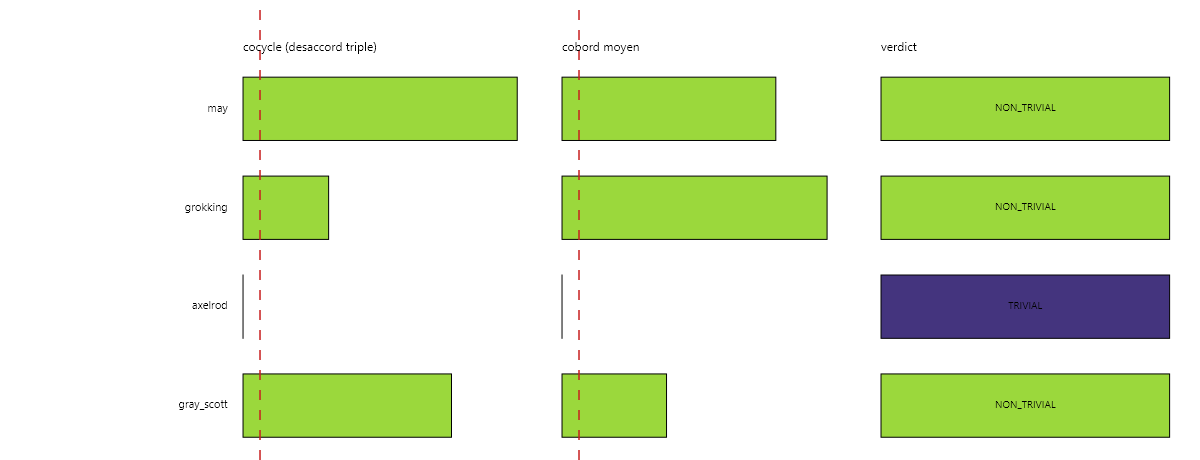


Recapitulatif :


    substrat |  cocycle |   ratio |   sign |   s2/s1 |     verdict


--------------------------------------------------------------------------


  gray_scott |   0.6140 |  1.9948 | 0.6333 |  0.1855 | NON_TRIVIAL


     axelrod |   0.0000 |  0.0000 | 0.0000 |  0.0000 |     TRIVIAL


    grokking |   0.2521 |  0.3229 | 0.6667 |  0.5692 | NON_TRIVIAL


         may |   0.8075 |  1.2824 | 0.6000 |  0.3762 | NON_TRIVIAL



Substrats NON_TRIVIAL : 3/4


Rappel : le verdict porte sur le cocycle ; s2/s1 est un temoin de forme.



warning CS1701: Assuming assembly reference 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' used by 'Microsoft.DotNet.Interactive' matches identity 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' of 'Microsoft.AspNetCore.Html.Abstractions', you may need to supply runtime policy



In [6]:
// Visualisation : tableau recapitulatif + verdict, en trois panneaux.
// Le cocycle decide, le cobord et le verdict l'accompagnent. La dimensionnalite
// (SVD) reste rapportee dans le tableau comme temoin, elle ne porte pas la decision.
var noms = new List<string> { "gray_scott", "axelrod", "grokking", "may" };
var plt = new ScottPlot.Plot();
// Figure sans axes ni grille : tout est porte par les barres, les textes et le plancher.
plt.Grid.IsVisible = false;
plt.Axes.Bottom.IsVisible = false;
plt.Axes.Left.IsVisible = false;
plt.Axes.Top.IsVisible = false;
plt.Axes.Right.IsVisible = false;
plt.Axes.SetLimits(0, 3.95, -0.1, 4.55);

// Trois panneaux cote a cote, comme la source : cocycle, cobord, verdict.
// Une rangee par substrat, de bas en haut comme le barh de la source, son nom a gauche.
double scale = 0.85;                       // echelle commune des deux premiers panneaux
double[] panneauX = { 0.80, 1.85, 2.90 };  // bord gauche de chaque panneau
double largeur = 0.95;                     // largeur utile d'un panneau
double demiHauteur = 0.32;

// Un rectangle ScottPlot se definit par ses bornes : X1 (gauche), X2 (droite),
// Y1 (bas), Y2 (haut). Elles sont posees explicitement, une par une.
Func<double, double, double, double, ScottPlot.Plottables.Rectangle> Rectangle =
    (left, right, bottom, top) =>
    {
        var rectangle = new ScottPlot.Plottables.Rectangle
        {
            X1 = left, X2 = right, Y1 = bottom, Y2 = top,
            LineColor = Palette.Noir,
            LineWidth = 1
        };
        plt.Add.Plottable(rectangle);
        return rectangle;
    };

for (int row = 0; row < noms.Count; row++)
{
    var (rep, verdict) = substratReports[noms[row]];
    double y = 0.45 + row;
    var fill = verdict == "NON_TRIVIAL" ? Palette.Viridis(0.85) : Palette.Viridis(0.15);

    // Panneau 1 : cocycle (la quantite qui decide). Panneau 2 : cobord.
    Rectangle(panneauX[0], panneauX[0] + rep.MeanCocycle / scale * largeur,
              y - demiHauteur, y + demiHauteur).FillColor = fill;
    Rectangle(panneauX[1], panneauX[1] + rep.MeanCoboundary / scale * largeur,
              y - demiHauteur, y + demiHauteur).FillColor = fill;

    // Panneau 3 : barre de verdict uniforme, le texte au centre.
    Rectangle(panneauX[2], panneauX[2] + largeur, y - demiHauteur, y + demiHauteur).FillColor = fill;
    var texteVerdict = plt.Add.Text(verdict, panneauX[2] + largeur / 2, y);
    texteVerdict.LabelFontSize = 10;
    texteVerdict.LabelFontColor = Palette.Noir;
    texteVerdict.Alignment = ScottPlot.Alignment.MiddleCenter;

    var nomSubstrat = plt.Add.Text(noms[row], panneauX[0] - 0.05, y);
    nomSubstrat.LabelFontSize = 11;
    nomSubstrat.LabelFontColor = Palette.Noir;
    nomSubstrat.Alignment = ScottPlot.Alignment.MiddleRight;
}

// Plancher 0.05, en pointilles rouges sur les deux panneaux de mesure (les
// deux axvline de la source). Seul le plancher du cocycle entre dans le
// verdict ; sur le panneau du cobord il est reproduit a l'identique pour la
// lecture de l'echelle et ne porte aucune decision.
for (int p = 0; p < 2; p++)
{
    var plancher = new ScottPlot.Plottables.VerticalLine
    {
        X = panneauX[p] + 0.05 / scale * largeur,
        LineColor = new ScottPlot.Color(200, 30, 30),
        LinePattern = ScottPlot.LinePattern.Dashed,
        LineWidth = 1.5f
    };
    plt.Add.Plottable(plancher);
}

string[] titres = { "cocycle (desaccord triple)", "cobord moyen", "verdict" };
for (int p = 0; p < 3; p++)
{
    var titre = plt.Add.Text(titres[p], panneauX[p], 4.15);
    titre.LabelFontSize = 12;
    titre.LabelFontColor = Palette.Noir;
}

display(HTML(plt.GetPngHtml(1200, 460)));

// Recapitulatif textuel.
Console.WriteLine("\nRecapitulatif :");
Console.WriteLine($"{"substrat",12} | {"cocycle",8} | {"ratio",7} | {"sign",6} | {"s2/s1",7} | {"verdict",11}");
Console.WriteLine(new string('-', 74));
int nNonTrivial = 0;
foreach (var nom in noms)
{
    var (r, v) = substratReports[nom];
    if (v == "NON_TRIVIAL") nNonTrivial++;
    Console.WriteLine($"{nom,12} | {r.MeanCocycle,8:F4} | {r.ObstructionRatio,7:F4} | " +
                      $"{r.SignConsistency,6:F4} | {r.S2OverS1,7:F4} | {v,11}");
}
Console.WriteLine($"\nSubstrats NON_TRIVIAL : {nNonTrivial}/{noms.Count}");
Console.WriteLine("Rappel : le verdict porte sur le cocycle ; s2/s1 est un temoin de forme.");

## Lecture 5 -- Verdict : 3 substrats NON_TRIVIAL sur quatre

Le récapitulatif affiche « Substrats NON_TRIVIAL : 3/4 » : gray_scott, grokking et may portent une obstruction Čech locale, axelrod est classé TRIVIAL. Le verdict est porté par le cocycle triple : may (`MeanCocycle` = 0.8075), gray_scott (0.6140) et grokking (0.2521) portent un cocycle non nul et directionnellement cohérent (`SignConsistency` de 0.6000 à 0.6667). Le contrôle négatif est **axelrod** : cocycle nul à la précision machine (`0.000E+000` en notation scientifique, soit 0.0000 à quatre décimales ; ratio 0.0000, sign 0.0000), `s2_over_s1` 0.0000 et rang 1.

> **Mesure honnête du périmètre.** Sur ce jeu de données, le cocycle et le rang **concordent partout** : axelrod a un rang 1, donc aucune des deux règles ne le déclarerait obstrué. Le carnet démontre que le cocycle *suffit* à trancher les quatre substrats ; il ne démontre pas qu'il est *nécessaire* de le préférer au rang — cela demanderait un substrat à rang élevé et cocycle nul, absent de ce banc, et la source Python ne l'obtenait que par un artefact de plancher (lecture 4).

Le verdict est donc mesuré sur quatre substrats de natures différentes (diffusion, réplicateur, marche biaisée, biomasse stochastique), avec un témoin négatif interne. C'est la réponse du carnet à la question sota-not-workaround : l'outil (classe d'obstruction de Čech) discrimine des trajectoires réelles non triviales — il n'est pas un workaround dégradé, et la couche Čech est calculée sur des types .NET natifs, sans bibliothèque de calcul numérique.

### Exercice 1 — Banc de robustesse : stabilité du verdict selon `window_size`

Le verdict dépend du choix de `window_size`. Tester 5 valeurs différentes pour le substrat
le plus prometteur (celui rendu `NON_TRIVIAL` ou le plus proche du seuil). Pour chaque valeur :
rapporter `MeanCocycle`, `ObstructionRatio`, `SignConsistency` et le verdict.

**Question** : le verdict est-il **stable** sur le substrat concerné ? Si oui, l'obstruction est
robuste à l'échelle de fenêtrage ; sinon, c'est un artefact du choix initial.

In [7]:
// Exercice 1 — Banc de robustesse selon window_size
// TODO etudiant : choisir le substrat le plus prometteur et tester 5 valeurs de
// window_size. Indice : Stats.Linspace(debut, fin, 5) pour 5 valeurs
// equidistantes ; pour chaque valeur, reutiliser Cech.ProxySections,
// Cech.ObstructionClass et Cech.Verdict. Remplir le resultat ci-dessous et
// conclure sur la stabilite du verdict.
string substratTest = null;   // ex: "may" ou celui rendu NON_TRIVIAL ci-dessus
var resultatsRobustesse = new List<(int windowSize, double cocycle, double ratio, double sign, string verdict)>();

if (substratTest != null)
{
    var (statesTest, nsTest) = substratsInfo[substratTest];
    // ... votre code ici ...
}

Console.WriteLine(resultatsRobustesse.Count == 0
    ? "A completer : tester 5 valeurs de window_size sur le substrat choisi."
    : $"Robustesse : {resultatsRobustesse.Count} valeurs testees.");

A completer : tester 5 valeurs de window_size sur le substrat choisi.


### Exercice 2 — Disqualifier un proxy : impact sur le verdict

La définition du verdict porte sur le cocycle triple (`MeanCocycle`, `ObstructionRatio`, `SignConsistency`) ; la dimensionnalité SVD reste rapportée comme témoin, elle ne décide plus.
Si un proxy est **constant** sur la trajectoire (variance nulle), il ne contribue pas à la
structure. Vérifier pour chaque substrat : y a-t-il un proxy constant sur certaines fenêtres ?
Si oui, ce proxy disqualifié change-t-il le verdict ?

**Question** : la disqualification d'un proxy est-elle **jamais justifiée** par son incapacité
à discriminer les fenêtres ? (sinon, ce n'est pas une obstruction, c'est un proxy mort).

In [8]:
// Exercice 2 — Disqualifier un proxy
// TODO etudiant : pour chaque substrat, calculer la variance de chaque section.
// Si une section a une variance nulle (ou tres petite, < 1e-6), le proxy est
// disqualifie sur ce substrat. Recalculer le verdict sans ce proxy et voir s'il
// change. Indice : Stats.StdPop(section) eleve au carre ; reconstruire le
// dictionnaire de sections sans la cle concernee, puis Cech.ObstructionClass.
var disqualifications = new Dictionary<string, List<string>>();

foreach (var kv in substratSections)
{
    // ... votre code ici ...
}

Console.WriteLine(disqualifications.Count == 0
    ? "A completer : identifier les proxys constants et recalculer les verdicts."
    : $"Proxys disqualifies : {disqualifications.Count} substrat(s) concerne(s).");

A completer : identifier les proxys constants et recalculer les verdicts.


### Exercice 3 — Acceptance finale : décision expérimentale qui change

Reprendre les résultats des cellules précédentes et formuler **une phrase** sur la manière
dont la lecture-obstruction change une décision expérimentale (cf acceptance #7744).

Exemples de décisions qui changent :
- Reclasser un substrat de « régime à dispersion » à « régime à obstruction structurelle »
- Choisir un proxy plutôt qu'un autre pour résumer le substrat (le proxy disqualifié ne
  servait qu'à mesurer du bruit)
- Justifier l'ajout d'un quatrième proxy pour avoir effectivement au moins deux dimensions non triviales
- Conclure que la cochaîne de Čech est l'outil pertinent (vs Phase Zéro) pour ce substrat

In [9]:
// Exercice 3 — Phrase de conclusion sur la decision qui change
// TODO etudiant : formuler une phrase precise reliant le verdict a au moins un
// changement de decision experimentale (cf exercice ci-dessus).
string phraseDecision = "";

Console.WriteLine($"Phrase de conclusion : {(string.IsNullOrEmpty(phraseDecision) ? "(vide)" : phraseDecision)}");

Phrase de conclusion : (vide)


## Vérifiez votre compréhension

1. Le banc synthétique passe **huit seeds sur huit** (TRIVIAL et NON_TRIVIAL discriminés), et le verdict réel donne **3 substrats NON_TRIVIAL sur quatre**. Pourquoi le sanity check synthétique précède-t-il le banc réel, et que prouve-t-il — que ne prouve-t-il pas ?
2. Gray-Scott rend `ObstructionRatio = 1.9948` avec `window_size = 136`, tandis qu'Axelrod tombe à un cocycle de 0.0000. Ce contraste de verdict vient-il de la taille de fenêtre (136 contre 13) ou de la structure des trajectoires ? S'appuyer sur ce que la lecture 4 mesure pour axelrod.
3. L'exercice 2 disqualifie un proxy à variance nulle : quel substrat du banc deviendrait TRIVIAL si l'on retirait son proxy le plus discriminant, et pourquoi l'acceptance #7744 exige-t-elle plus qu'un verdict descriptif ?

## À retenir

**Objet testé** : cochaîne de Čech pondérée appliquée à quatre substrats (Gray-Scott, Axelrod,
Grokking, May), trois proxys par substrat (`spectral_gap`, `sens_mean`, `sens_max`), fenêtrage contigu adaptatif.

**Verdict par substrat** : voir le tableau récapitulatif de la cellule de visualisation. Le verdict `NON_TRIVIAL` indique
que les proxys ne se réduisent pas à un signal latent 1D sur ce substrat ; le verdict `TRIVIAL`
indique qu'ils se recollent en une mesure globale unique (l'obstruction n'est pas constatée).

**Acceptance #7744** : si au moins un substrat rend `NON_TRIVIAL`, l'acceptance positive est partiellement
atteinte — le candidat cochaîne de Čech **démontre sa capacité à discriminer** (cf sanity check).
L'acceptance complète exige que la lecture-obstruction **change une décision expérimentale ou une
visualisation** (cf exercice 3) ; sans cette formulation, le verdict reste descriptif.

**Limites honnêtes** :
- Le verdict dépend du choix de `window_size` (tester la robustesse, exercice 1).
- Un proxy disqualifié (variance nulle) peut fausser le verdict (exercice 2).
- Trois proxys seulement : le rang effectif (SVD) est plafonné à trois. Le verdict ne s'y adosse plus — il porte sur le cocycle — mais la comparaison de forme entre substrats reste bornée par ce plafond.
  Passer à quatre proxys ou plus permettrait une lecture plus riche de la structure multi-dimensionnelle.

**Remplacements déclarés de ce jumeau** : le générateur numpy PCG64 est remplacé par un xorshift64\* seedé (Box-Muller pour la loi normale), la décomposition en valeurs singulières (`np.linalg.svd`) par les valeurs propres de la matrice de Gram M Mᵀ, de taille 3×3 ici, dont les racines carrées sont les valeurs singulières, et le tirage Dirichlet(50) du réplicateur par une uniforme perturbée renormalisée. Les quatre verdicts sont ceux de la source ; les valeurs numériques des substrats stochastiques, et le champ initial de Gray-Scott, dépendent du générateur et sont comparées à tolérance de Monte-Carlo — elles sont reportées côte à côte dans la fiche de paire.

## Références et provenance

- Issue de suivi [#7744](https://github.com/jsboige/CoursIA/issues/7744) ; jambe transverse [#7395](https://github.com/jsboige/CoursIA/issues/7395) de la série ICT [#4588](https://github.com/jsboige/CoursIA/issues/4588).
- Module source : `ict.cech_obstruction` ; PR d'implémentation #8828.
- ICT-15c : PR #9328 ; corrections de sensibilité #9770, #9766 et #9776.
- Jumeau C# : paire enregistrée dans `scripts/notebook_tools/twin_pairs.d/`.

## Pour aller plus loin

- La suite immédiate teste la discriminabilité temporelle de la réparation : [ICT-15e — Bridge #2](ICT-15e-Bridge2-RecoverabilityAgency-Python.ipynb).
- La source Python de ce carnet : [ICT-15d — Obstruction Čech (Python)](ICT-15d-CechObstruction-Python.ipynb).
- Le nerf (b1) comme discriminant, et l'observable plat d'Axelrod : [ICT-15j](ICT-15j-NerveDiscriminant-Python.ipynb).
- La phase zéro dont ce carnet hérite : [ICT-15c](ICT-15c-MetaProxyObstruction-Python.ipynb).
- Revenir au [cadrage de la série](../ICT-0-Framing.md).